### Lab 6: Part 2
#### Name: Anna Phillips

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv('./data/diabetes.csv', index_col = 0)

df.head()

,treatment,outcome
1,met,success
2,rosi,failure
3,rosi,success
4,lifestyle,success
5,met,success


#### **1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups?**

In [37]:
## Crosstabs, average treatment effect:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

df["outcome"] = df["outcome"].map({
    "success": 1,
    "failure": 0
})

print(f'Lifestyle mean: {df.loc[df['treatment'] == 'lifestyle', 'outcome'].mean():.3f}')
print(f'Rosi mean: {df.loc[df['treatment'] == 'rosi', 'outcome'].mean():.3f}')
print(f'Met mean: {df.loc[df['treatment'] == 'met', 'outcome'].mean():.3f}')
print()

ate1 = df.loc[ df['treatment'] == 'lifestyle', 'outcome'].mean() \
    - df.loc[ df['treatment'] == 'met', 'outcome'].mean() 

ate2 = df.loc[ df['treatment'] == 'rosi', 'outcome'].mean() \
    - df.loc[ df['treatment'] == 'lifestyle', 'outcome'].mean() 

ate3 = df.loc[ df['treatment'] == 'rosi', 'outcome'].mean() \
    - df.loc[ df['treatment'] == 'met', 'outcome'].mean() 

print('Estimated ATE (lifestyle - met): ', np.round(ate1, 3))
print('Estimated ATE (rosi - lifestyle): ', np.round(ate2, 3))
print('Estimated ATE (rosi - met): ', np.round(ate3, 3))

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Lifestyle mean: 0.534
Rosi mean: 0.614
Met mean: 0.483

Estimated ATE (lifestyle - met):  0.051
Estimated ATE (rosi - lifestyle):  0.08
Estimated ATE (rosi - met):  0.131


***Answer (1):*** 

#### **2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms.** 


In [39]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['treatment'] == 'lifestyle',:]
df_b = df.loc[ df['treatment'] == 'rosi',:]
df_c = df.loc[ df['treatment'] == 'met',:]

outcome_a = []
outcome_b = []
outcome_c = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)


    ## Evaluate outcomes:
    oat = df_at['outcome'].mean() # Mean outcome for A
    obt = df_bt['outcome'].mean() # Mean outcome for B   
    oct = df_ct['outcome'].mean() # Mean outcome for B   

    ## Compute ATE:
    ate_ab = oat - obt # Compute ATE for this bootstrap sample
    ate_ac = oat - oct # Compute ATE for this bootstrap sample
    ate_bc = obt - oct # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    outcome_c.append(oct) # Save new value
    ate.append(ate_ab) # Save new value
    ate.append(ate_ac) # Save new value
    ate.append(ate_ac) # Save new value

#### **3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.**

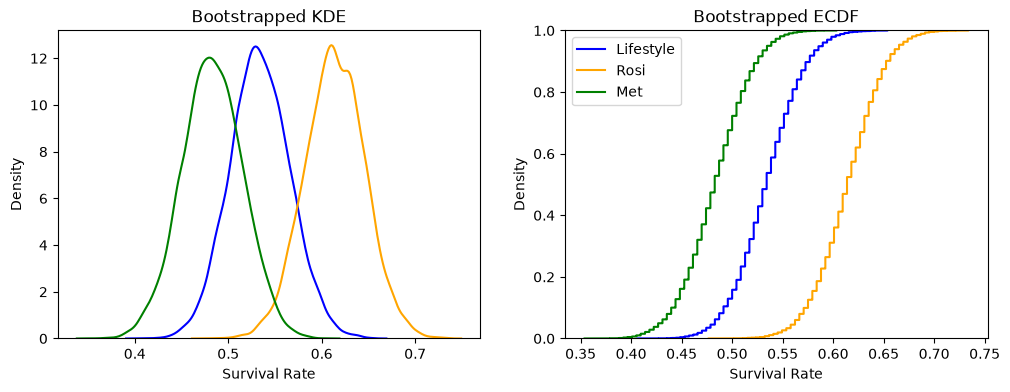

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Lifestyle', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Rosi', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')
sns.kdeplot(outcome_c, label='Met', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Lifestyle', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Rosi', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')
sns.ecdfplot(outcome_c, label='Met', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

#### **4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.**


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()

#### **5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?**

#### **6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.**